# Structure Profiling — QC Summary

Exploratory quality-control (QC) report over the chains profiled by the **structure_profiling**
pipeline. Stage 5 (`bin/5_qc.sh`) runs six QC pipelines over every protein chain of `chain_pdb`
(first model, `pro_len > 3`) and keeps one further pipeline (`chain_fixed_breaks.py`) for the
repaired chains of `chain_fixed`. Results land in the tables defined by `src/sql/qc.sql`:

| # | check | pipeline (`src/pipelines/qc/`) | result table | key statistics |
|---|-------|-------------------------------|--------------|----------------|
| 1 | covalent bond lengths | `chain_bonds.py` | `chain_bonds` | `bond_rmsz`, `bond_z_outlier_frac`, `bond_max_absz` |
| 2 | chain continuity | `chain_breaks.py` | `chain_breaks` | `num_missing`, `num_breaks`, `num_fragments`, `num_strained`, `ca_max_dist`, `pep_max_dist` |
| 3 | continuity after repair | `chain_fixed_breaks.py` | `chain_fixed_breaks` | same as (2), computed on `chain_fixed` |
| 4 | C-beta deviation | `chain_cbeta.py` | `chain_cbeta` | `cb_max_dev`, `cb_outlier_frac` |
| 5 | CA chirality | `chain_chirality.py` | `chain_chirality` | `n_chirality_outliers`, `chirality_outlier_frac` |
| 6 | steric clashes | `chain_clashes.py` | `chain_clashes` | `clash_score`, `vdw_clash_score`, `num_severe_clashes`, `max_overlap` |
| 7 | backbone torsions / angles | `chain_torsions.py` | `chain_torsions` | `angle_rmsz`, cis/trans, Ramachandran, planarity |

**Contents**

1. Database connection & table loading
2. Gate / cutoff inventory (as embedded in the QC modules)
3. Bond lengths — 4. Chain breaks — 5. Fixed-chain breaks — 6. C-beta deviation
7. CA chirality — 8. Steric clashes — 9. Backbone torsions
10. Gate pass rates & threshold recommendations
11. Combined per-chain QC verdict
12. QC evaluation flowcharts
13. Conclusions

In [1]:
import sys, time, logging, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
logging.getLogger('matplotlib.category').setLevel(logging.ERROR)
sns.set_theme(style='whitegrid', context='notebook')
mpl.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 11, 'axes.labelsize': 10})
pd.set_option('display.max_columns', 50)

# locate the project root regardless of the kernel working directory
ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from structure_profiling.database import QueryComplex

# .env (MYSQL_HOST / MYSQL_USER / MYSQL_PASSWORD / MYSQL_DB) is loaded by the db module itself
db = QueryComplex(verbose=True)
print('project root :', ROOT)
print('database     :', db.config.get('database'), 'on', db.config.get('host'))

C_MAIN, C_BAD, C_OK, C_WARN = '#5b8ff9', '#dc2626', '#22c55e', '#f59e0b'


def vline(ax, x, label, color=C_BAD):
    ax.axvline(x, color=color, ls='--', lw=1.5, label=label)
    ax.legend(frameon=True)


def count_bar(ax, s, xmax=10, color=C_MAIN):
    # value counts of an integer column on a log axis, tail folded into "> xmax"
    vc = s.value_counts()
    keys = sorted(k for k in vc.index if not isinstance(k, str) and k <= xmax)
    vals = [int(vc[k]) for k in keys]
    over = int(sum(v for k, v in vc.items() if isinstance(k, str) or k > xmax))
    if over:
        keys.append('>' + str(xmax))
        vals.append(over)
    ax.bar([str(k) for k in keys], vals, color=color)
    ax.set_yscale('log')
    for x, v in enumerate(vals):
        if v:
            ax.text(x, v, f'{v:,}', ha='center', va='bottom', fontsize=7)


print('setup ok')

project root : /home/yuan/bio/structure_profiling
database     : COMPLEX2 on am5
setup ok


## 1. Load the QC result tables

All seven tables are pulled in full; `chain_fixed_breaks` is expected to be missing (its
pipeline is not wired into `bin/5_qc.sh`), so the loader degrades gracefully for it.

In [2]:
QC_TABLES = ['chain_bonds', 'chain_breaks', 'chain_fixed_breaks', 'chain_cbeta',
             'chain_chirality', 'chain_clashes', 'chain_torsions']

T = {}
for t in QC_TABLES:
    if not db.table_exists(t):
        print(f'!! {t}: table missing — pipeline not run / not populated yet')
        T[t] = None
        continue
    t0 = time.time()
    T[t] = db.list_data(f'SELECT * FROM {t}', is_df=True)
    df = T[t]
    print(f'{t:20s} {len(df):>9,} rows x {df.shape[1]:2d} cols   ({time.time() - t0:5.1f} s)')

main = T['chain_torsions']
if main is not None:
    print(f'\nreference set: {len(main):,} chains in chain_torsions')

INFO:mysql.connector:package: mysql.connector.plugins


INFO:mysql.connector:plugin_name: caching_sha2_password


INFO:mysql.connector:AUTHENTICATION_PLUGIN_CLASS: MySQLCachingSHA2PasswordAuthPlugin


chain_bonds            766,864 rows x  7 cols   (  4.5 s)


chain_breaks           766,864 rows x  9 cols   (  4.5 s)
!! chain_fixed_breaks: table missing — pipeline not run / not populated yet


chain_cbeta            766,864 rows x  6 cols   (  3.8 s)


chain_chirality        766,864 rows x  6 cols   (  3.4 s)


chain_clashes          240,265 rows x  9 cols   (  1.5 s)


chain_torsions         766,864 rows x 19 cols   (  7.8 s)

reference set: 766,864 chains in chain_torsions


## 2. Gate inventory

All cutoffs live in the QC / geometry modules, not in the SQL layer:

- `structure/clashes.py` (`Clashes`) — clash cutoff 2.4 A, severe 2.0 A, clashscore gate 30, MolProbity poor band 20, `VDW_OVERLAP_CUT = 0.40 A`
- `qc/breaks.py` (`Breaks`) — `cn_break = 2.0 A`, `ca_break = 4.5 A`, `cn_strain = 1.5 A`
- `qc/torsions.py` (`Torsions`) — `Z_OUTLIER_CUT = 5`, `CIS_CUT = 90 deg`, `OMEGA_DEV_CUT = 30 deg`, `MAINCHAIN_OOP_CUT = 10 deg`
- `qc/geometry_distance.py` (`GeometryDistance`) — `Z_OUTLIER_CUT = 5`, `CB_DEVIATION_CUT = 0.25 A`
- `qc/geometry_angle.py` (`GeometryAngle`) — `CHIRAL_VOL_L = 2.6 A^3`, `CHIRAL_VOL_MIN = 0.7 A^3`

The table below is the single source of truth used for every gate evaluation in this notebook
(sections 10-11).

In [3]:
GATES = pd.DataFrame([
    # check, table, metric, gate, sense, source module, note
    ('Bond lengths', 'chain_bonds', 'bond_rmsz', 2.0, 'le', 'geometry_distance.py', 'wwPDB expects RMS-Z in [0, 1]'),
    ('Bond lengths', 'chain_bonds', 'bond_z_outlier_frac', 0.01, 'le', 'geometry_distance.py', 'outliers at |Z| > 5, bond half'),
    ('Chain breaks', 'chain_breaks', 'num_missing', 0, 'eq', 'qc/breaks.py', 'residues lacking N/CA/C/O'),
    ('Chain breaks', 'chain_breaks', 'num_breaks', 0, 'eq', 'qc/breaks.py', 'C-N > 2.0 A or CA-CA > 4.5 A'),
    ('Chain breaks', 'chain_breaks', 'num_fragments', 1, 'eq', 'qc/breaks.py', '= 1 + num_breaks'),
    ('Chain breaks', 'chain_breaks', 'num_strained', 3, 'le', 'qc/breaks.py', '1.5 A < C-N <= 2.0 A'),
    ('Chain breaks', 'chain_breaks', 'ca_max_dist', 5.0, 'le', 'qc/breaks.py', 'ideal CA-CA ~ 3.8 A'),
    ('Chain breaks', 'chain_breaks', 'pep_max_dist', 5.0, 'le', 'qc/breaks.py', 'ideal C-N 1.329 A'),
    ('C-beta deviation', 'chain_cbeta', 'cb_outlier_frac', 0.05, 'le', 'geometry_distance.py', 'CB dev > 0.25 A is an outlier'),
    ('CA chirality', 'chain_chirality', 'n_chirality_outliers', 0, 'eq', 'geometry_angle.py', 'D + planar CA centres'),
    ('Steric clashes', 'chain_clashes', 'clash_score', 30.0, 'le', 'structure/clashes.py', 'clashes / 1000 heavy atoms'),
    ('Steric clashes', 'chain_clashes', 'vdw_clash_score', 20.0, 'le', 'structure/clashes.py', 'MolProbity clashscore poor band'),
    ('Steric clashes', 'chain_clashes', 'num_severe_clashes', 0, 'eq', 'structure/clashes.py', 'contacts < 2.0 A'),
    ('Backbone torsions', 'chain_torsions', 'angle_rmsz', 1.5, 'le', 'qc/torsions.py', 'bond-angle RMS-Z'),
    ('Backbone torsions', 'chain_torsions', 'z_outlier_frac', 0.01, 'le', 'qc/torsions.py', 'outliers at |Z| > 5, angle half'),
    ('Backbone torsions', 'chain_torsions', 'torsion_null_frac', 0.05, 'le', 'qc/torsions.py', 'phi/psi/omega undefined'),
    ('Backbone torsions', 'chain_torsions', 'peptide_outlier_frac', 0.05, 'le', 'qc/torsions.py', '|omega dev| > 30 deg'),
    ('Backbone torsions', 'chain_torsions', 'mainchain_outlier_frac', 0.05, 'le', 'qc/torsions.py', 'out-of-plane > 10 deg'),
    ('Backbone torsions', 'chain_torsions', 'rama_outlier_frac', 0.05, 'le', 'qc/torsions.py', 'Ramachandran outliers'),
], columns=['check', 'table', 'metric', 'gate', 'sense', 'source', 'note'])
GATES

,check,table,metric,gate,sense,source,note
0,Bond lengths,chain_bonds,bond_rmsz,2.00,le,geometry_distance.py,"wwPDB expects RMS-Z in [0, 1]"
1,Bond lengths,chain_bonds,bond_z_outlier_frac,0.01,le,geometry_distance.py,"outliers at |Z| > 5, bond half"
2,Chain breaks,chain_breaks,num_missing,0.00,eq,qc/breaks.py,residues lacking N/CA/C/O
3,Chain breaks,chain_breaks,num_breaks,0.00,eq,qc/breaks.py,C-N > 2.0 A or CA-CA > 4.5 A
4,Chain breaks,chain_breaks,num_fragments,1.00,eq,qc/breaks.py,= 1 + num_breaks
5,Chain breaks,chain_breaks,num_strained,3.00,le,qc/breaks.py,1.5 A < C-N <= 2.0 A
6,Chain breaks,chain_breaks,ca_max_dist,5.00,le,qc/breaks.py,ideal CA-CA ~ 3.8 A
7,Chain breaks,chain_breaks,pep_max_dist,5.00,le,qc/breaks.py,ideal C-N 1.329 A
8,C-beta deviation,chain_cbeta,cb_outlier_frac,0.05,le,geometry_distance.py,CB dev > 0.25 A is an outlier
9,CA chirality,chain_chirality,n_chirality_outliers,0.00,eq,geometry_angle.py,D + planar CA centres


## 3. Covalent bond lengths (`chain_bonds`)

Z-scores of the backbone bond lengths (N-CA, CA-C, C-O, CA-CB and the C(i)-N(i+1) peptide
bridge) against the Engh & Huber ideals in `qc/geometry_distance.py` (`IDEAL_BONDS`).

Embedded gates: `bond_rmsz <= 2.0` (former `BACKBONE_GATES`; wwPDB expects RMS-Z in
**[0, 1]**) and `bond_z_outlier_frac <= 0.01`, with outliers at `|Z| > 5`
(`Z_OUTLIER_CUT`).

,bond_rmsz,bond_z_outlier_frac,bond_max_absz
count,764018.000,766864.000,766864.000
mean,9.273,0.001,290.340
std,18.398,0.009,590.369
min,0.021,0.000,0.000
50%,0.598,0.000,2.750
95%,42.619,0.004,1387.187
99%,77.859,0.020,2642.161
99.9%,165.242,0.158,5129.672
max,995.786,0.763,15712.200


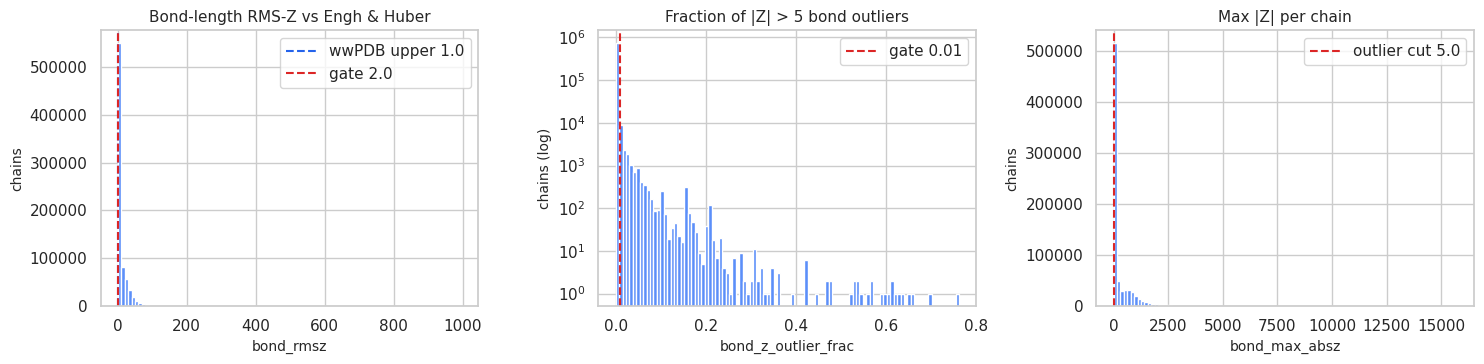

bond_rmsz <= 2.0           :  64.73% pass   (wwPDB-strict <= 1.0: 61.96%)
bond_z_outlier_frac <= 0.01:  98.32% pass
both bond gates            :  64.46% pass


In [4]:
df = T['chain_bonds']
display(df[['bond_rmsz', 'bond_z_outlier_frac', 'bond_max_absz']]
        .describe(percentiles=[0.5, 0.95, 0.99, 0.999]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

ax = axes[0]
ax.hist(df['bond_rmsz'].dropna(), bins=100, color=C_MAIN)
vline(ax, 1.0, 'wwPDB upper 1.0', color='#2563eb')
vline(ax, 2.0, 'gate 2.0')
ax.set(title='Bond-length RMS-Z vs Engh & Huber', xlabel='bond_rmsz', ylabel='chains')

ax = axes[1]
ax.hist(df['bond_z_outlier_frac'].dropna(), bins=100, color=C_MAIN)
vline(ax, 0.01, 'gate 0.01')
ax.set_yscale('log')
ax.set(title='Fraction of |Z| > 5 bond outliers', xlabel='bond_z_outlier_frac', ylabel='chains (log)')

ax = axes[2]
ax.hist(df['bond_max_absz'].dropna(), bins=100, color=C_MAIN)
vline(ax, 5.0, 'outlier cut 5.0')
ax.set(title='Max |Z| per chain', xlabel='bond_max_absz', ylabel='chains')

plt.tight_layout()
plt.show()

r = df['bond_rmsz'] <= 2.0
f = df['bond_z_outlier_frac'] <= 0.01
print(f'bond_rmsz <= 2.0           : {r.mean():7.2%} pass   (wwPDB-strict <= 1.0: {(df["bond_rmsz"] <= 1.0).mean():.2%})')
print(f'bond_z_outlier_frac <= 0.01: {f.mean():7.2%} pass')
print(f'both bond gates            : {(r & f).mean():7.2%} pass')

## 4. Chain continuity (`chain_breaks`)

`Breaks.run()` per chain: residues missing backbone atoms (N/CA/C/O), peptide breaks
(`C-N > 2.0 A` or `CA-CA > 4.5 A`), fragments (= 1 + breaks), strained peptides
(`1.5 A < C-N <= 2.0 A`), plus the longest observed CA-CA and C-N distances.

Embedded gates: `num_missing = 0`, `num_breaks = 0`, `num_fragments = 1`,
`num_strained <= 3`, `ca_max_dist <= 5.0 A`, `pep_max_dist <= 5.0 A`.

,num_missing,num_breaks,num_fragments,num_strained,ca_max_dist,pep_max_dist
count,766864.000,766864.000,766864.000,766864.000,766864.000,766864.000
mean,1.143,2.121,3.121,0.007,7.312,5.383
std,24.722,23.322,23.322,0.232,7.601,8.271
min,0.000,0.000,1.000,0.000,3.660,0.000
50%,0.000,0.000,1.000,0.000,3.890,1.360
95%,0.000,6.000,7.000,0.000,21.140,20.750
99%,1.000,15.000,16.000,0.000,38.620,38.320
max,3303.000,3302.000,3303.000,74.000,220.870,221.300


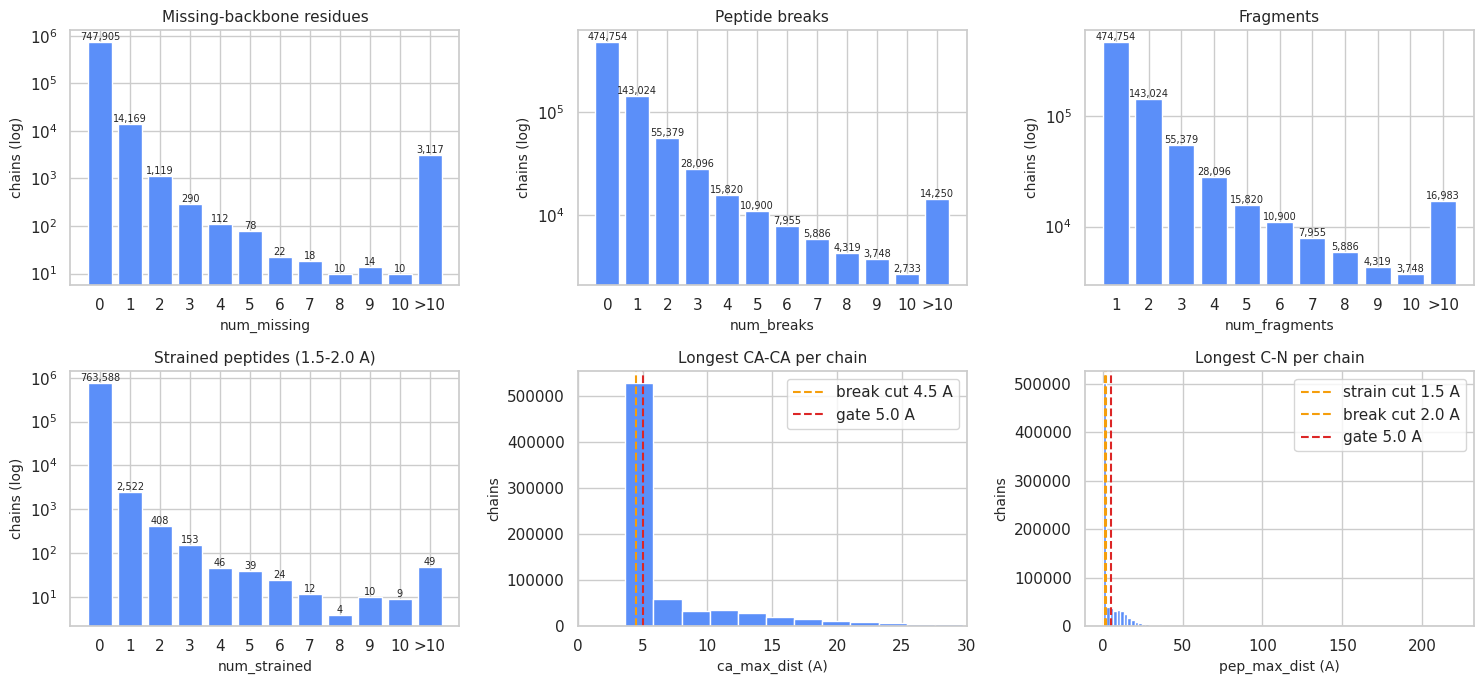

num_missing = 0       :  97.53% pass
num_breaks = 0        :  61.91% pass
num_fragments = 1     :  61.91% pass
num_strained <= 3     :  99.97% pass
ca_max_dist <= 5.0    :  65.74% pass
pep_max_dist <= 5.0   :  72.44% pass
ALL break gates       :  60.76% pass


In [5]:
df = T['chain_breaks']
display(df[['num_missing', 'num_breaks', 'num_fragments', 'num_strained',
            'ca_max_dist', 'pep_max_dist']]
        .describe(percentiles=[0.5, 0.95, 0.99]).round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, col, title in zip(
        axes.flat,
        ['num_missing', 'num_breaks', 'num_fragments', 'num_strained'],
        ['Missing-backbone residues', 'Peptide breaks', 'Fragments', 'Strained peptides (1.5-2.0 A)']):
    count_bar(ax, df[col], xmax=10)
    ax.set(title=title, xlabel=col, ylabel='chains (log)')

ax = axes.flat[4]
ax.hist(df['ca_max_dist'].dropna(), bins=100, color=C_MAIN)
vline(ax, 4.5, 'break cut 4.5 A', color=C_WARN)
vline(ax, 5.0, 'gate 5.0 A')
ax.set(title='Longest CA-CA per chain', xlabel='ca_max_dist (A)', ylabel='chains')
ax.set_xlim(0, 30)

ax = axes.flat[5]
ax.hist(df['pep_max_dist'].dropna(), bins=100, color=C_MAIN)
vline(ax, 1.5, 'strain cut 1.5 A', color=C_WARN)
vline(ax, 2.0, 'break cut 2.0 A', color=C_WARN)
vline(ax, 5.0, 'gate 5.0 A')
ax.set(title='Longest C-N per chain', xlabel='pep_max_dist (A)', ylabel='chains')

plt.tight_layout()
plt.show()

gates = {
    'num_missing = 0':       df['num_missing'] == 0,
    'num_breaks = 0':        df['num_breaks'] == 0,
    'num_fragments = 1':     df['num_fragments'] == 1,
    'num_strained <= 3':     df['num_strained'] <= 3,
    'ca_max_dist <= 5.0':    df['ca_max_dist'] <= 5.0,
    'pep_max_dist <= 5.0':   df['pep_max_dist'] <= 5.0,
}
for name, ok in gates.items():
    print(f'{name:22s}: {ok.mean():7.2%} pass')
print(f'{"ALL break gates":22s}: {np.logical_and.reduce(list(gates.values())).mean():7.2%} pass')

## 5. Chain continuity after repair (`chain_fixed_breaks`)

`chain_fixed_breaks.py` re-runs the continuity check on the PDBFixer-repaired chains of
`chain_fixed`. The pipeline exists (`src/pipelines/qc/chain_fixed_breaks.py`) but is **not
invoked by `bin/5_qc.sh`**, so the table is not populated yet; the cell below degrades
gracefully and will produce the plots once the table is filled.

In [6]:
df = T['chain_fixed_breaks']
if df is None:
    print('chain_fixed_breaks is missing/empty — nothing to plot yet.')
    print('run:  parallel -j8 uv run sp chain_fixed_breaks ::: {0..258}')
else:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    count_bar(axes[0], df['num_breaks'], xmax=10)
    axes[0].set(title='Breaks per chain (repaired)', xlabel='num_breaks', ylabel='chains (log)')
    count_bar(axes[1], df['num_fragments'], xmax=10)
    axes[1].set(title='Fragments per chain (repaired)', xlabel='num_fragments', ylabel='chains (log)')
    axes[2].hist(df['ca_max_dist'].dropna(), bins=80, color=C_MAIN)
    vline(axes[2], 5.0, 'gate 5.0 A')
    axes[2].set(title='Longest CA-CA per chain (repaired)', xlabel='ca_max_dist (A)', ylabel='chains')
    plt.tight_layout()
    plt.show()
    m = (df['num_breaks'] == 0) & (df['num_fragments'] == 1)
    print(f'repaired chains fully continuous: {m.mean():.2%}')

chain_fixed_breaks is missing/empty — nothing to plot yet.
run:  parallel -j8 uv run sp chain_fixed_breaks ::: {0..258}


## 6. C-beta deviation (`chain_cbeta`)

MolProbity-style CB deviation: distance between the observed CB and the position idealised on
the N/CA/C frame (`CB_BOND_LEN = 1.521 A`, `CB_ANGLE = 110 deg`). Residues with
`cb_dev > 0.25 A` (`CB_DEVIATION_CUT`) are outliers; gate `cb_outlier_frac <= 0.05`;
glycines carry no CB and are excluded from `n_cb_analysed`.

,cb_max_dev,cb_outlier_frac
count,766864.000,766864.000
mean,0.255,0.005
std,0.155,0.019
min,0.000,0.000
50%,0.235,0.000
95%,0.391,0.022
99%,0.630,0.075
99.9%,2.035,0.250
max,58.420,1.000


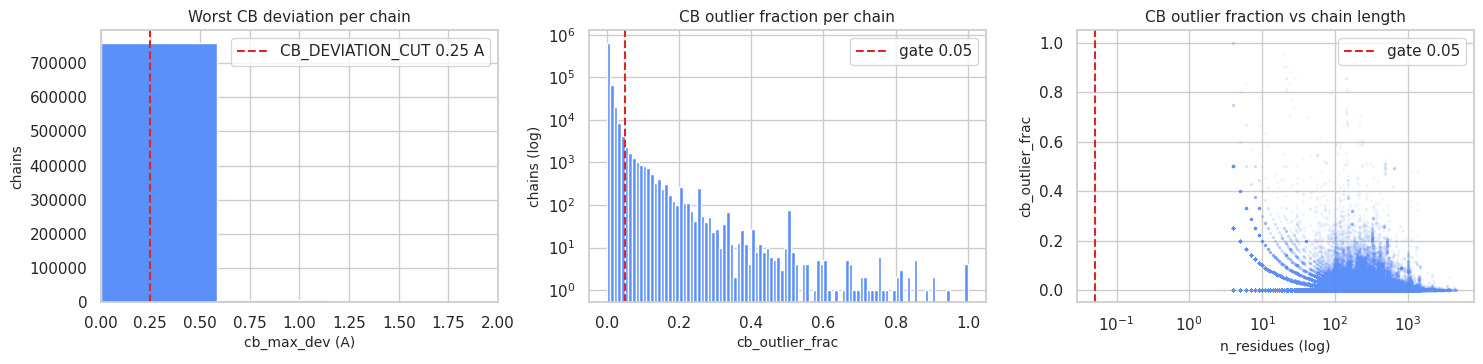

cb_outlier_frac <= 0.05: 98.42% pass
chains whose worst CB dev > 0.25 A: 36.68%


In [7]:
df = T['chain_cbeta']
display(df[['cb_max_dev', 'cb_outlier_frac']]
        .describe(percentiles=[0.5, 0.95, 0.99, 0.999]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

ax = axes[0]
ax.hist(df['cb_max_dev'].dropna(), bins=100, color=C_MAIN)
vline(ax, 0.25, 'CB_DEVIATION_CUT 0.25 A')
ax.set(title='Worst CB deviation per chain', xlabel='cb_max_dev (A)', ylabel='chains')
ax.set_xlim(0, 2)

ax = axes[1]
ax.hist(df['cb_outlier_frac'].dropna(), bins=100, color=C_MAIN)
vline(ax, 0.05, 'gate 0.05')
ax.set_yscale('log')
ax.set(title='CB outlier fraction per chain', xlabel='cb_outlier_frac', ylabel='chains (log)')

ax = axes[2]
ax.scatter(df['n_residues'], df['cb_outlier_frac'], s=2, alpha=0.05, color=C_MAIN)
vline(ax, 0.05, 'gate 0.05')
ax.set_xscale('log')
ax.set(title='CB outlier fraction vs chain length', xlabel='n_residues (log)', ylabel='cb_outlier_frac')

plt.tight_layout()
plt.show()

g = df['cb_outlier_frac'] <= 0.05
print(f'cb_outlier_frac <= 0.05: {g.mean():.2%} pass')
print(f'chains whose worst CB dev > 0.25 A: {(df["cb_max_dev"] > 0.25).mean():.2%}')

## 7. CA chirality (`chain_chirality`)

Handedness of every CA centre from the signed N-CA-C-CB chiral volume: ideal L volume
`CHIRAL_VOL_L = 2.6 A^3`, planar centres at `0 < vol < 0.7 A^3` (`CHIRAL_VOL_MIN`),
D-amino acids at `vol < 0`, glycine `NA`.

Gate: `n_chirality_outliers = 0` (D + planar CA centres in an L-amino-acid chain).

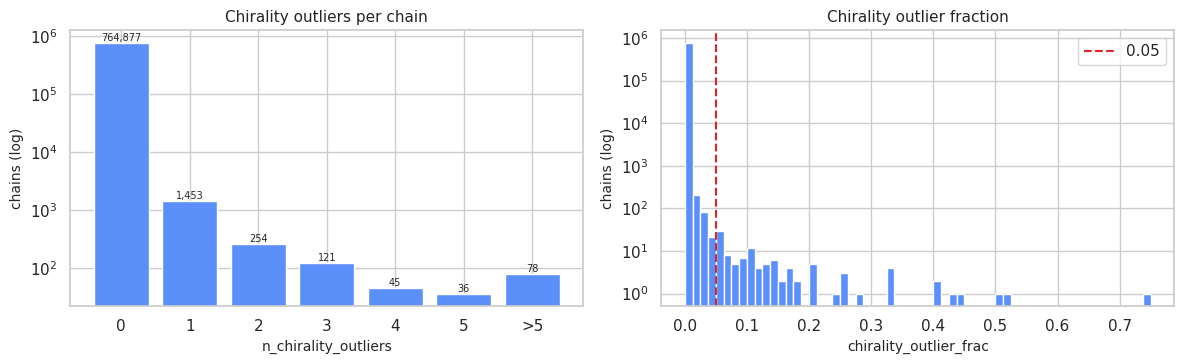

chains with >= 1 chirality outlier: 1,987 (0.259%)


,pdb_id,chain_id,n_residues,n_chirality_outliers,chirality_outlier_frac
162370,3IYF,3IYF_0_A_0,491,58,0.128
162376,3IYF,3IYF_0_G_0,491,53,0.117
162385,3IYF,3IYF_0_P_0,491,52,0.115
162377,3IYF,3IYF_0_H_0,491,50,0.110
162378,3IYF,3IYF_0_I_0,491,50,0.110
162384,3IYF,3IYF_0_O_0,491,49,0.108
162373,3IYF,3IYF_0_D_0,491,47,0.104
162375,3IYF,3IYF_0_F_0,491,47,0.104
162380,3IYF,3IYF_0_K_0,491,47,0.104
162382,3IYF,3IYF_0_M_0,491,47,0.104


In [8]:
df = T['chain_chirality']

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

count_bar(axes[0], df['n_chirality_outliers'], xmax=5)
axes[0].set(title='Chirality outliers per chain', xlabel='n_chirality_outliers', ylabel='chains (log)')

axes[1].hist(df['chirality_outlier_frac'].dropna(), bins=60, color=C_MAIN)
vline(axes[1], 0.05, '0.05')
axes[1].set_yscale('log')
axes[1].set(title='Chirality outlier fraction', xlabel='chirality_outlier_frac', ylabel='chains (log)')

plt.tight_layout()
plt.show()

n_bad = int((df['n_chirality_outliers'] > 0).sum())
print(f'chains with >= 1 chirality outlier: {n_bad:,} ({n_bad / len(df):.3%})')
if n_bad:
    display(df[df['n_chirality_outliers'] > 0]
            .nlargest(10, 'n_chirality_outliers')
            [['pdb_id', 'chain_id', 'n_residues', 'n_chirality_outliers', 'chirality_outlier_frac']])

## 8. Steric clashes (`chain_clashes`)

`Clashes.run()`: non-bonded heavy-atom contacts below `clash_cutoff = 2.4 A` are clashes,
below `2.0 A` severe; `clash_score` = clashes / 1000 heavy atoms; the MolProbity-style
`vdw_clash_score` counts vdW overlaps `>= 0.40 A` (`VDW_OVERLAP_CUT`) per 1000 heavy atoms
(hydrogens excluded); `max_overlap` is the largest overlap.

Gates: `clash_score <= 30`, `vdw_clash_score <= 20` (MolProbity poor band), and
`num_severe_clashes = 0`.

coverage: 240,265 of 766,864 reference chains (31.3%) — the clash pipeline covers fewer chains


,num_clashes,num_severe_clashes,clash_score,vdw_clash_score,max_overlap
count,240265.000,240265.000,240265.000,240265.000,240265.000
mean,2.347,0.180,1.042,8.511,0.691
std,7.796,2.337,3.348,10.076,0.345
min,0.000,0.000,0.000,0.000,0.000
50%,1.000,0.000,0.230,6.460,0.668
95%,10.000,1.000,3.940,22.630,1.199
99%,24.000,4.000,9.240,45.400,1.925
max,624.000,270.000,448.600,763.240,3.400


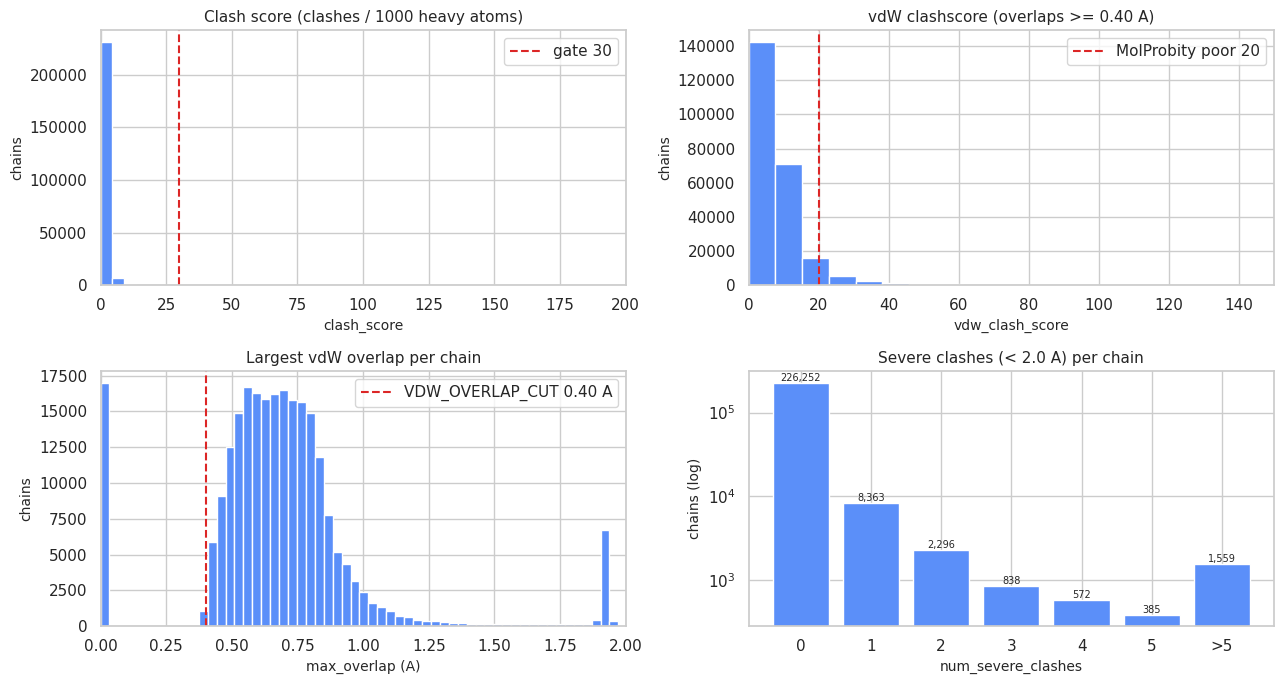

clash_score <= 30       :  99.88% pass
vdw_clash_score <= 20   :  93.50% pass
num_severe_clashes = 0  :  94.17% pass
ALL clash gates         :  89.46% pass


In [9]:
df = T['chain_clashes']
n_ref = len(T['chain_torsions'])
print(f'coverage: {len(df):,} of {n_ref:,} reference chains ({len(df) / n_ref:.1%}) — '
      'the clash pipeline covers fewer chains')

display(df[['num_clashes', 'num_severe_clashes', 'clash_score',
            'vdw_clash_score', 'max_overlap']]
        .describe(percentiles=[0.5, 0.95, 0.99]).round(3))

fig, axes = plt.subplots(2, 2, figsize=(13, 7))

ax = axes[0, 0]
ax.hist(df['clash_score'].dropna(), bins=100, color=C_MAIN)
vline(ax, 30, 'gate 30')
ax.set(title='Clash score (clashes / 1000 heavy atoms)', xlabel='clash_score', ylabel='chains')
ax.set_xlim(0, 200)

ax = axes[0, 1]
ax.hist(df['vdw_clash_score'].dropna(), bins=100, color=C_MAIN)
vline(ax, 20, 'MolProbity poor 20')
ax.set(title='vdW clashscore (overlaps >= 0.40 A)', xlabel='vdw_clash_score', ylabel='chains')
ax.set_xlim(0, 150)

ax = axes[1, 0]
ax.hist(df['max_overlap'].dropna(), bins=100, color=C_MAIN)
vline(ax, 0.40, 'VDW_OVERLAP_CUT 0.40 A')
ax.set(title='Largest vdW overlap per chain', xlabel='max_overlap (A)', ylabel='chains')
ax.set_xlim(0, 2)

count_bar(axes[1, 1], df['num_severe_clashes'], xmax=5)
axes[1, 1].set(title='Severe clashes (< 2.0 A) per chain', xlabel='num_severe_clashes', ylabel='chains (log)')

plt.tight_layout()
plt.show()

gates = {
    'clash_score <= 30':        df['clash_score'] <= 30,
    'vdw_clash_score <= 20':    df['vdw_clash_score'] <= 20,
    'num_severe_clashes = 0':   df['num_severe_clashes'] == 0,
}
for name, ok in gates.items():
    print(f'{name:24s}: {ok.mean():7.2%} pass')
print(f'{"ALL clash gates":24s}: {np.logical_and.reduce(list(gates.values())).mean():7.2%} pass')

## 9. Backbone torsions & bond angles (`chain_torsions`)

`Torsions.run()`: bond-angle RMS-Z vs ideal values (`angle_rmsz`, gate 1.5; outliers at
`|Z| > 5`), omega cis/trans split (`CIS_CUT = 90 deg`), MolProbity-style Ramachandran
fractions, and wwPDB peptide (`|omega dev| > 30 deg`) / main-chain (out-of-plane
`> 10 deg`) planarity outlier fractions. Gates: `angle_rmsz <= 1.5`,
`z_outlier_frac <= 0.01`, `torsion_null_frac <= 0.05`, `peptide_outlier_frac <= 0.05`,
`mainchain_outlier_frac <= 0.05`, `rama_outlier_frac <= 0.05`.

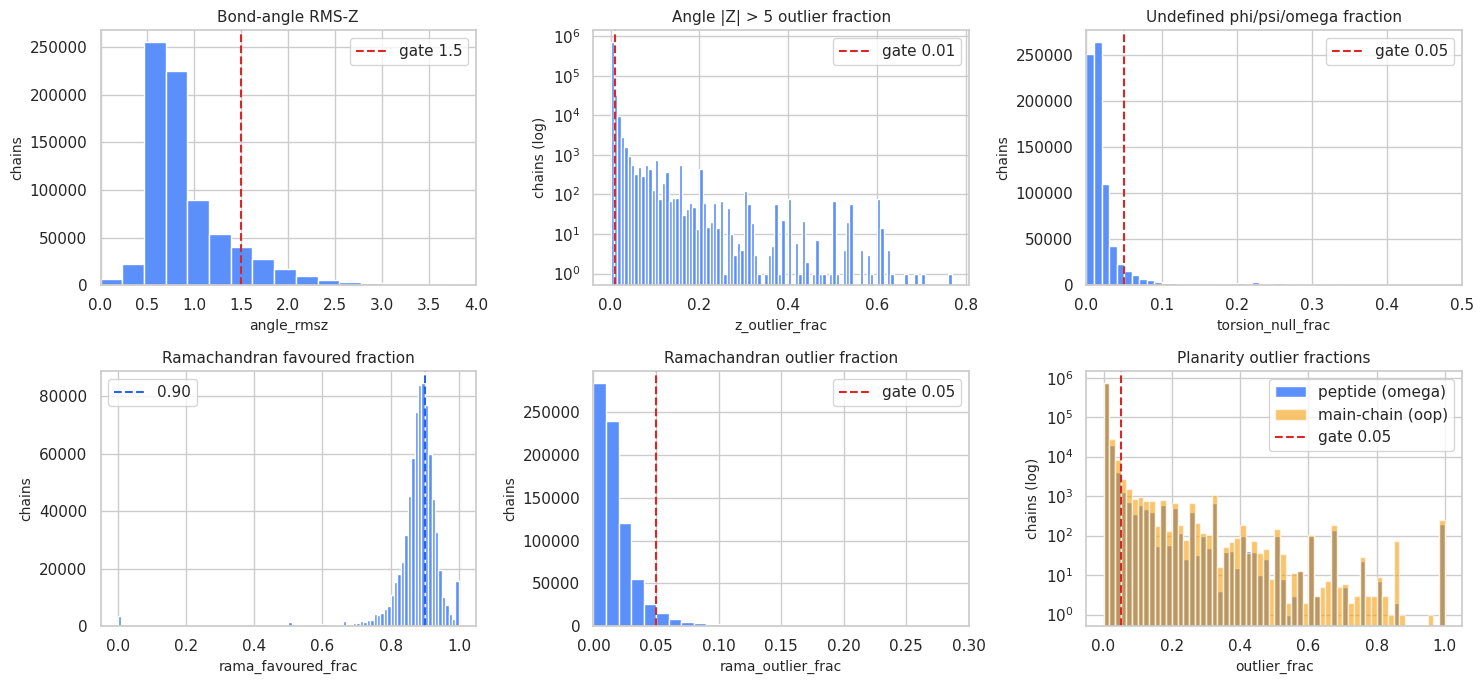

angle_rmsz <= 1.5             :  87.82% pass
z_outlier_frac <= 0.01        :  95.24% pass
torsion_null_frac <= 0.05     :  90.29% pass
peptide_outlier_frac <= 0.05  :  99.07% pass
mainchain_outlier_frac<=0.05  :  98.31% pass
rama_outlier_frac <= 0.05     :  94.75% pass
ALL torsion gates             :  77.89% pass

cis peptides: mean frac_cis = 0.0026, chains with a non-Pro cis peptide: 33.772%


In [10]:
df = T['chain_torsions']

fig, axes = plt.subplots(2, 3, figsize=(15, 7))

ax = axes[0, 0]
ax.hist(df['angle_rmsz'].dropna(), bins=100, color=C_MAIN)
vline(ax, 1.5, 'gate 1.5')
ax.set(title='Bond-angle RMS-Z', xlabel='angle_rmsz', ylabel='chains')
ax.set_xlim(0, 4)

ax = axes[0, 1]
ax.hist(df['z_outlier_frac'].dropna(), bins=100, color=C_MAIN)
vline(ax, 0.01, 'gate 0.01')
ax.set_yscale('log')
ax.set(title='Angle |Z| > 5 outlier fraction', xlabel='z_outlier_frac', ylabel='chains (log)')

ax = axes[0, 2]
ax.hist(df['torsion_null_frac'].dropna(), bins=100, color=C_MAIN)
vline(ax, 0.05, 'gate 0.05')
ax.set(title='Undefined phi/psi/omega fraction', xlabel='torsion_null_frac', ylabel='chains')
ax.set_xlim(0, 0.5)

ax = axes[1, 0]
ax.hist(df['rama_favoured_frac'].dropna(), bins=100, color=C_MAIN)
vline(ax, 0.90, '0.90', color='#2563eb')
ax.set(title='Ramachandran favoured fraction', xlabel='rama_favoured_frac', ylabel='chains')

ax = axes[1, 1]
ax.hist(df['rama_outlier_frac'].dropna(), bins=100, color=C_MAIN)
vline(ax, 0.05, 'gate 0.05')
ax.set(title='Ramachandran outlier fraction', xlabel='rama_outlier_frac', ylabel='chains')
ax.set_xlim(0, 0.3)

ax = axes[1, 2]
ax.hist(df['peptide_outlier_frac'].dropna(), bins=60, color=C_MAIN, label='peptide (omega)')
ax.hist(df['mainchain_outlier_frac'].dropna(), bins=60, color=C_WARN, alpha=0.6, label='main-chain (oop)')
vline(ax, 0.05, 'gate 0.05')
ax.set_yscale('log')
ax.set(title='Planarity outlier fractions', xlabel='outlier_frac', ylabel='chains (log)')
ax.legend(frameon=True)

plt.tight_layout()
plt.show()

gates = {
    'angle_rmsz <= 1.5':            df['angle_rmsz'] <= 1.5,
    'z_outlier_frac <= 0.01':       df['z_outlier_frac'] <= 0.01,
    'torsion_null_frac <= 0.05':    df['torsion_null_frac'] <= 0.05,
    'peptide_outlier_frac <= 0.05': df['peptide_outlier_frac'] <= 0.05,
    'mainchain_outlier_frac<=0.05': df['mainchain_outlier_frac'] <= 0.05,
    'rama_outlier_frac <= 0.05':    df['rama_outlier_frac'] <= 0.05,
}
for name, ok in gates.items():
    print(f'{name:30s}: {ok.mean():7.2%} pass')
print(f'{"ALL torsion gates":30s}: {np.logical_and.reduce(list(gates.values())).mean():7.2%} pass')

print(f"\ncis peptides: mean frac_cis = {df['frac_cis'].mean():.4f}, "
      f"chains with a non-Pro cis peptide: {(df['n_cis_nonpro'] > 0).mean():.3%}")

## 10. Gate pass rates & threshold recommendations

Every embedded gate is evaluated against the observed chain population: the fraction of
chains inside the gate and where the gate sits in the empirical distribution. An automatic
verdict classifies each gate:

- **lenient** — `>= 99.9%` of chains pass: the gate barely bites; candidates for tightening (p99 / p99.9 shown)
- **well placed** — `98-99.9%` pass: flags a small, genuine tail
- **tail visible** — `90-98%` pass: a non-trivial share is flagged; inspect whether these are real defects
- **strict** — `< 90%` pass: the gate dominates; either the data systematically violates it or the gate assumes near-ideal models

Caveats: gates are *validity* thresholds (they must catch bad geometry), not quantiles of a
well-behaved distribution — a lenient verdict alone is not an argument for loosening a gate.
Quantile columns are most informative for the continuous metrics.

In [11]:
def gate_stats(row):
    df = T[row.table]
    if df is None:
        return pd.Series({'check': row.check, 'metric': row.metric, 'gate': row.gate,
                          'sense': row.sense, 'n': 0, 'median': np.nan, 'p95': np.nan,
                          'p99': np.nan, 'p999': np.nan, 'frac_pass': np.nan,
                          'verdict': 'table missing', 'note': row.note})
    s = pd.to_numeric(df[row.metric], errors='coerce').dropna()
    ok = (s <= row.gate) if row.sense == 'le' else (s == row.gate)
    qs = s.quantile([0.5, 0.95, 0.99, 0.999])
    frac = float(ok.mean())
    if frac >= 0.999:
        verdict = 'lenient'
    elif frac >= 0.98:
        verdict = 'well placed'
    elif frac >= 0.90:
        verdict = 'tail visible'
    else:
        verdict = 'strict'
    return pd.Series({'check': row.check, 'metric': row.metric, 'gate': row.gate,
                      'sense': row.sense, 'n': len(s), 'median': qs[0.5], 'p95': qs[0.95],
                      'p99': qs[0.99], 'p999': qs[0.999], 'frac_pass': frac,
                      'verdict': verdict, 'note': row.note})


RECO = GATES.apply(gate_stats, axis=1)
RECO[['median', 'p95', 'p99', 'p999']] = RECO[['median', 'p95', 'p99', 'p999']].round(3)
RECO['frac_pass'] = RECO['frac_pass'].round(5)
RECO

,check,metric,gate,sense,n,median,p95,p99,p999,frac_pass,verdict,note
0,Bond lengths,bond_rmsz,2.00,le,764018,0.598,42.619,77.859,165.242,0.64973,strict,"wwPDB expects RMS-Z in [0, 1]"
1,Bond lengths,bond_z_outlier_frac,0.01,le,766864,0.000,0.004,0.020,0.158,0.98318,well placed,"outliers at |Z| > 5, bond half"
2,Chain breaks,num_missing,0.00,eq,766864,0.000,0.000,1.000,390.000,0.97528,tail visible,residues lacking N/CA/C/O
3,Chain breaks,num_breaks,0.00,eq,766864,0.000,6.000,15.000,384.000,0.61909,strict,C-N > 2.0 A or CA-CA > 4.5 A
4,Chain breaks,num_fragments,1.00,eq,766864,1.000,7.000,16.000,385.000,0.61909,strict,= 1 + num_breaks
5,Chain breaks,num_strained,3.00,le,766864,0.000,0.000,0.000,1.000,0.99975,lenient,1.5 A < C-N <= 2.0 A
6,Chain breaks,ca_max_dist,5.00,le,766864,3.890,21.140,38.620,73.723,0.65741,strict,ideal CA-CA ~ 3.8 A
7,Chain breaks,pep_max_dist,5.00,le,766864,1.360,20.750,38.320,73.141,0.72439,strict,ideal C-N 1.329 A
8,C-beta deviation,cb_outlier_frac,0.05,le,766864,0.000,0.022,0.075,0.250,0.98421,well placed,CB dev > 0.25 A is an outlier
9,CA chirality,n_chirality_outliers,0.00,eq,766864,0.000,0.000,0.000,1.000,0.99741,well placed,D + planar CA centres


In [12]:
print('verdict summary per gate:')
display(RECO.groupby('verdict')['metric'].count() if len(RECO) else RECO)

lenient = RECO[RECO['verdict'] == 'lenient']
if len(lenient):
    print('\nlenient gates — suggested tightened values (empirical p99 / p99.9):')
    display(lenient[['check', 'metric', 'gate', 'p99', 'p999', 'frac_pass']])

verdict summary per gate:


verdict
lenient         1
strict          6
tail visible    6
well placed     6
Name: metric, dtype: int64


lenient gates — suggested tightened values (empirical p99 / p99.9):


,check,metric,gate,p99,p999,frac_pass
5,Chain breaks,num_strained,3.0,0.0,1.0,0.99975


## 11. Combined per-chain QC verdict

All gates of section 10 are combined per chain on `chain_id` (outer join; a check that has no
row for a chain counts as *not covered*, not as failed). This mirrors the evaluation flow of
section 12 and yields a single per-chain verdict: **pass** when every covered check is
satisfied.

In [13]:
flags = {}

bd = T['chain_bonds'].set_index('chain_id')
flags['bonds'] = (bd['bond_rmsz'] <= 2.0) & (bd['bond_z_outlier_frac'] <= 0.01)

br = T['chain_breaks'].set_index('chain_id')
flags['breaks'] = ((br['num_missing'] == 0) & (br['num_breaks'] == 0)
                   & (br['num_fragments'] == 1) & (br['num_strained'] <= 3)
                   & (br['ca_max_dist'] <= 5.0) & (br['pep_max_dist'] <= 5.0))

cb = T['chain_cbeta'].set_index('chain_id')
flags['cbeta'] = cb['cb_outlier_frac'] <= 0.05

ch = T['chain_chirality'].set_index('chain_id')
flags['chirality'] = ch['n_chirality_outliers'] == 0

if T['chain_clashes'] is not None:
    cl = T['chain_clashes'].set_index('chain_id')
    flags['clashes'] = ((cl['clash_score'] <= 30) & (cl['vdw_clash_score'] <= 20)
                        & (cl['num_severe_clashes'] == 0))

to = T['chain_torsions'].set_index('chain_id')
flags['torsions'] = ((to['angle_rmsz'] <= 1.5) & (to['z_outlier_frac'] <= 0.01)
                     & (to['torsion_null_frac'] <= 0.05) & (to['peptide_outlier_frac'] <= 0.05)
                     & (to['mainchain_outlier_frac'] <= 0.05) & (to['rama_outlier_frac'] <= 0.05))

F = pd.DataFrame(flags)                    # True = pass, False = fail, NaN = not covered
covered = F.notna()
failed = (F == False)
n_checks = covered.sum(axis=1)
n_failed = failed.sum(axis=1)

print(f'chains with >= 1 covered check : {int((n_checks > 0).sum()):,}')
print(f'chains covered by all checks   : {int((n_checks == len(F.columns)).sum()):,}')
per_check = pd.DataFrame({'covered': covered.sum(), 'failed': failed.sum()})
per_check['fail_rate'] = (per_check['failed'] / per_check['covered']).round(5)
per_check

chains with >= 1 covered check : 766,864
chains covered by all checks   : 240,265


,covered,failed,fail_rate
bonds,766864,272550,0.35541
breaks,766864,300935,0.39242
cbeta,766864,12106,0.01579
chirality,766864,1987,0.00259
clashes,240265,25330,0.10543
torsions,766864,169547,0.22109


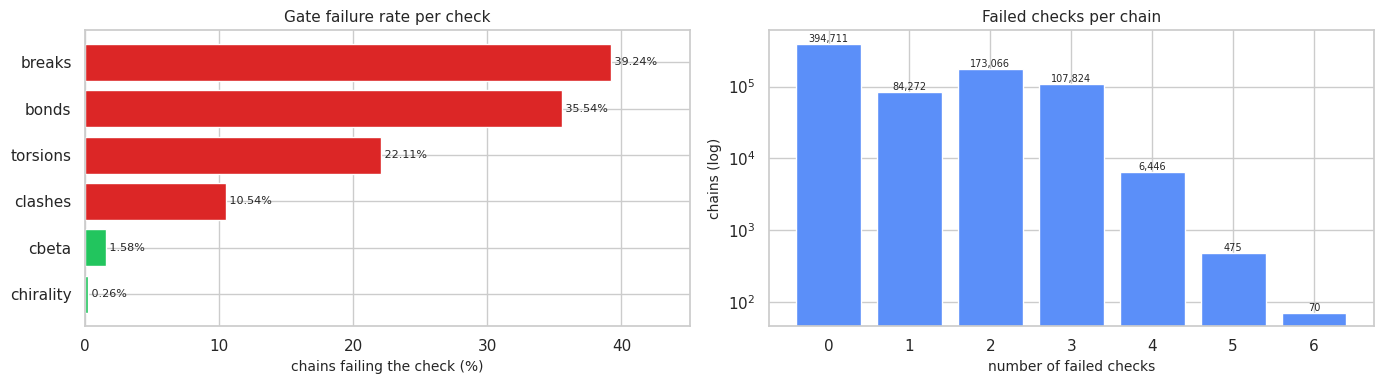

chains passing every covered check: 394,711 (51.47% of covered chains)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
order = per_check.sort_values('fail_rate').index
colors = [C_OK if per_check.loc[c, 'fail_rate'] < 0.02 else C_WARN if per_check.loc[c, 'fail_rate'] < 0.10 else C_BAD
          for c in order]
ax.barh(order, per_check.loc[order, 'fail_rate'] * 100, color=colors)
for i, c in enumerate(order):
    ax.text(per_check.loc[c, 'fail_rate'] * 100, i, f" {per_check.loc[c, 'fail_rate']:.2%}",
            va='center', fontsize=8)
ax.set(title='Gate failure rate per check', xlabel='chains failing the check (%)')
ax.set_xlim(0, max(per_check['fail_rate']) * 115)

ax = axes[1]
vc = n_failed[n_checks > 0].value_counts().sort_index()
ax.bar([str(int(k)) for k in vc.index], vc.values, color=C_MAIN)
ax.set_yscale('log')
for x, v in enumerate(vc.values):
    ax.text(x, v, f'{v:,}', ha='center', va='bottom', fontsize=7)
ax.set(title='Failed checks per chain', xlabel='number of failed checks', ylabel='chains (log)')

plt.tight_layout()
plt.show()

clean = int((n_failed == 0).sum())
print(f'chains passing every covered check: {clean:,} '
      f'({clean / max(int((n_checks > 0).sum()), 1):.2%} of covered chains)')

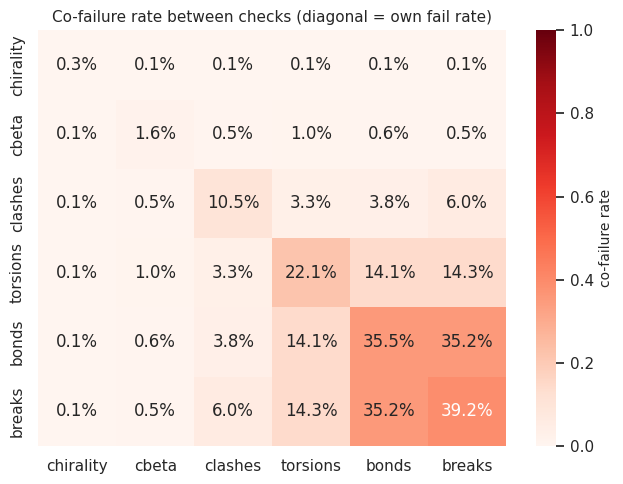

In [15]:
n_cov = covered.T.astype(int) @ covered.astype(int)
n_both = failed.T.astype(int) @ failed.astype(int)
with np.errstate(invalid='ignore', divide='ignore'):
    co = np.where(n_cov > 0, n_both / np.maximum(n_cov, 1), np.nan)
CO = pd.DataFrame(co, index=F.columns, columns=F.columns).reindex(index=order, columns=order)

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(CO, annot=True, fmt='.1%', cmap='Reds', vmin=0, vmax=1.0,
            cbar_kws={'label': 'co-failure rate'}, ax=ax)
ax.set_title('Co-failure rate between checks (diagonal = own fail rate)', fontsize=11)
plt.tight_layout()
plt.show()

In [16]:
summary = pd.DataFrame({
    'pdb_id': to['pdb_id'],
    'n_covered': n_checks,
    'n_failed': n_failed,
}).dropna(subset=['pdb_id'])
summary['n_covered'] = summary['n_covered'].astype(int)
summary['n_failed'] = summary['n_failed'].astype(int)
summary['failed_checks'] = failed.loc[summary.index].apply(
    lambda r: ', '.join(F.columns[np.asarray(r, dtype=bool)]), axis=1)

worst = summary.sort_values(['n_failed', 'n_covered'], ascending=[False, False]).head(15)
print('worst 15 chains by number of failed checks:')
display(worst)

print(f'\ndistinct PDB entries touched: {summary["pdb_id"].nunique():,}')
print('verdict distribution (covered chains only):')
display(n_failed[n_checks > 0].value_counts().sort_index().rename('chains').to_frame())

worst 15 chains by number of failed checks:


,pdb_id,n_covered,n_failed,failed_checks
chain_id,,,,
1ATP_0_E_0,1ATP,6,6,"bonds, breaks, cbeta, chirality, clashes, tors..."
1EA0_0_A_0,1EA0,6,6,"bonds, breaks, cbeta, chirality, clashes, tors..."
1GLC_0_F_0,1GLC,6,6,"bonds, breaks, cbeta, chirality, clashes, tors..."
1GLC_0_G_0,1GLC,6,6,"bonds, breaks, cbeta, chirality, clashes, tors..."
1GLD_0_F_0,1GLD,6,6,"bonds, breaks, cbeta, chirality, clashes, tors..."
1GLD_0_G_0,1GLD,6,6,"bonds, breaks, cbeta, chirality, clashes, tors..."
1GLE_0_G_0,1GLE,6,6,"bonds, breaks, cbeta, chirality, clashes, tors..."
1LVK_0_A_0,1LVK,6,6,"bonds, breaks, cbeta, chirality, clashes, tors..."
1MDA_0_M_0,1MDA,6,6,"bonds, breaks, cbeta, chirality, clashes, tors..."



distinct PDB entries touched: 239,191
verdict distribution (covered chains only):


,chains
0,394711
1,84272
2,173066
3,107824
4,6446
5,475
6,70


## 12. QC evaluation flowcharts

Two views of the QC machinery, drawn with plain matplotlib (no graphviz dependency):
**(a)** the stage-5 data flow from PDB entries to the seven result tables, and
**(b)** the per-chain gate evaluation logic implemented in sections 3–11.

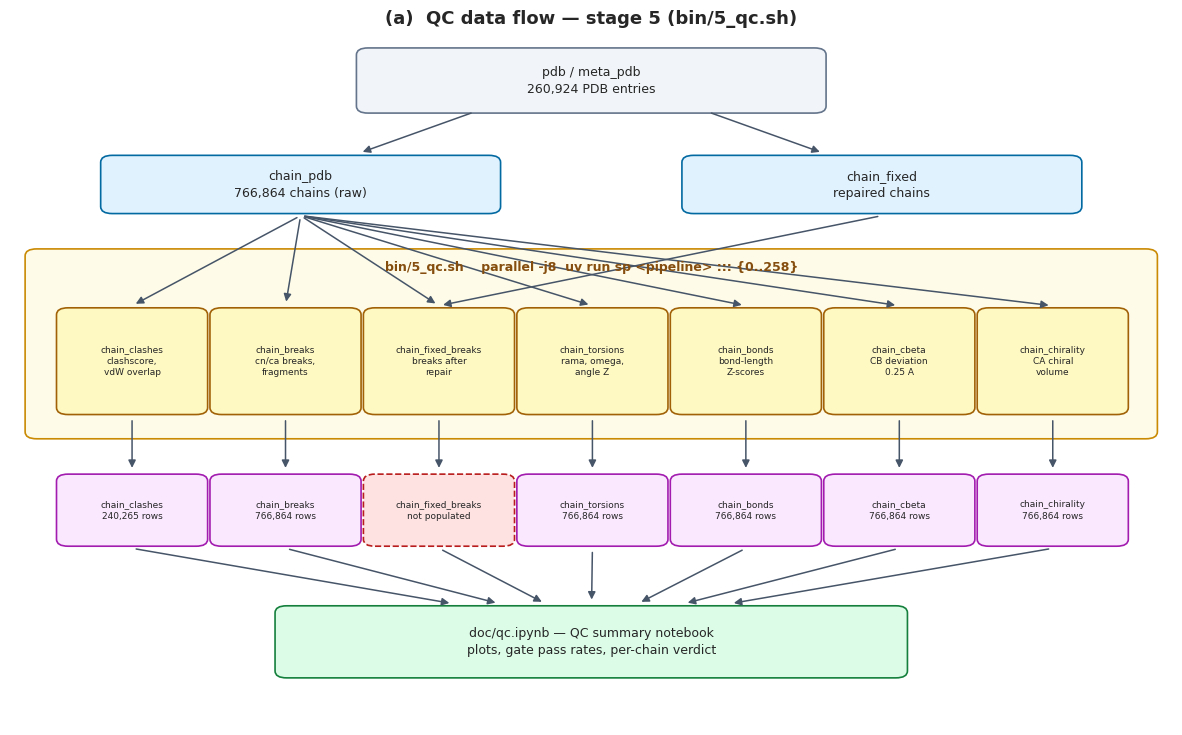

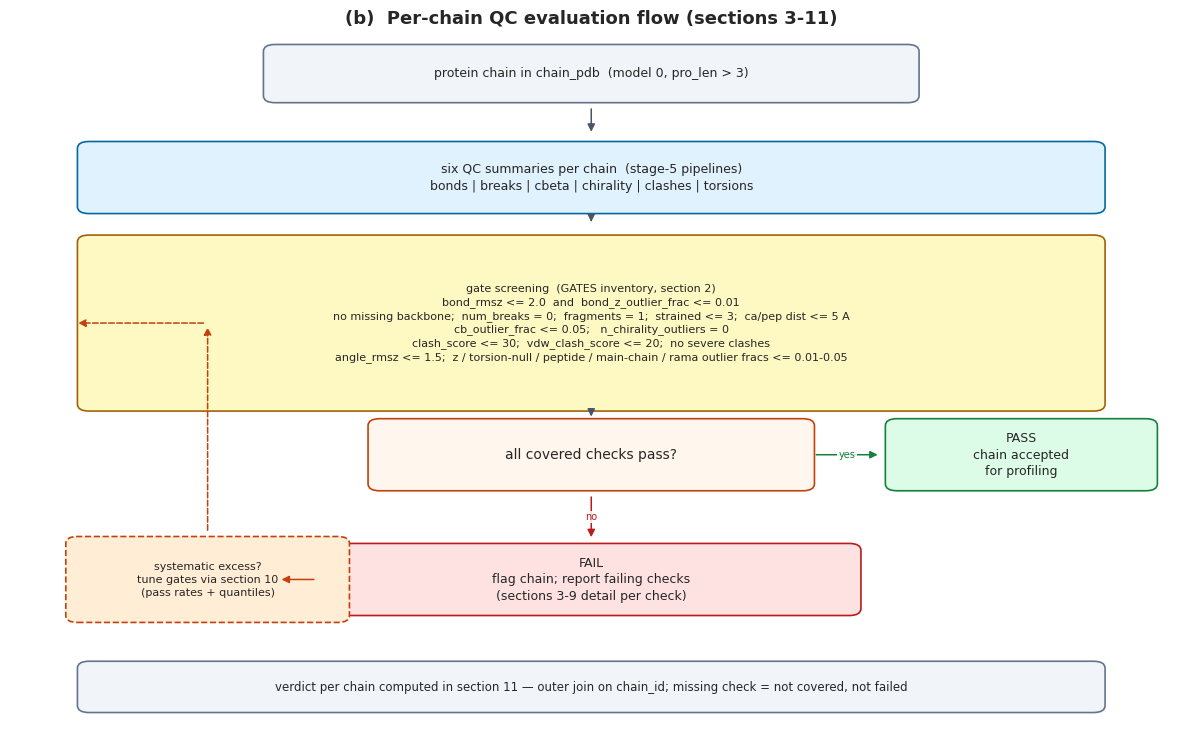

In [17]:
def flow_fig(figsize):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')
    return fig, ax


def fbox(ax, cx, cy, w, h, text, fc='#dbeafe', ec='#1e40af', fs=8, ls='-', lw=1.2):
    ax.add_patch(mpl.patches.FancyBboxPatch(
        (cx - w / 2, cy - h / 2), w, h,
        boxstyle='round,pad=0.02,rounding_size=0.1',
        fc=fc, ec=ec, lw=lw, linestyle=ls))
    ax.text(cx, cy, text, ha='center', va='center', fontsize=fs, linespacing=1.35)


def farrow(ax, x1, y1, x2, y2, text=None, ls='-', color='#475569', fs=7, rad=0.0):
    ax.add_patch(mpl.patches.FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=11,
        color=color, lw=1.1, linestyle=ls,
        connectionstyle=f'arc3,rad={rad}', shrinkA=3, shrinkB=3))
    if text:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, text, ha='center', va='center',
                fontsize=fs, color=color,
                bbox=dict(fc='white', ec='none', alpha=0.85, pad=1))


# ---- (a) stage-5 data flow -------------------------------------------------
fig, ax = flow_fig((15, 9))
ax.set_title('(a)  QC data flow — stage 5 (bin/5_qc.sh)', fontsize=13, weight='bold')

n_pdb = db.num_rows('meta_pdb')
fbox(ax, 5, 9.3, 4.0, 0.9, f'pdb / meta_pdb\n{n_pdb:,} PDB entries', '#f1f5f9', '#64748b', fs=9)
fbox(ax, 2.5, 7.8, 3.4, 0.8, f'chain_pdb\n{len(T["chain_torsions"]):,} chains (raw)', '#e0f2fe', '#0369a1', fs=9)
fbox(ax, 7.5, 7.8, 3.4, 0.8, 'chain_fixed\nrepaired chains', '#e0f2fe', '#0369a1', fs=9)
farrow(ax, 4.0, 8.85, 3.0, 8.25)
farrow(ax, 6.0, 8.85, 7.0, 8.25)

fbox(ax, 5, 5.5, 9.7, 2.7, '', '#fefce8', '#ca8a04')
ax.text(5, 6.55, 'bin/5_qc.sh    parallel -j8  uv run sp <pipeline> ::: {0..258}',
        ha='center', fontsize=9, color='#854d0e', weight='bold')

pipelines = [
    ('chain_clashes', 'clashscore,\nvdW overlap'),
    ('chain_breaks', 'cn/ca breaks,\nfragments'),
    ('chain_fixed_breaks', 'breaks after\nrepair'),
    ('chain_torsions', 'rama, omega,\nangle Z'),
    ('chain_bonds', 'bond-length\nZ-scores'),
    ('chain_cbeta', 'CB deviation\n0.25 A'),
    ('chain_chirality', 'CA chiral\nvolume'),
]
for i, (nm, sub) in enumerate(pipelines):
    x = 1.05 + i * 1.32
    fbox(ax, x, 5.25, 1.26, 1.5, nm + '\n' + sub, '#fef9c3', '#a16207', fs=6.5)
    farrow(ax, 2.5, 7.35, x, 6.05)
    if nm == 'chain_fixed_breaks':
        farrow(ax, 7.5, 7.35, x, 6.05)

for i, (nm, _) in enumerate(pipelines):
    x = 1.05 + i * 1.32
    n = len(T[nm]) if T.get(nm) is not None else 0
    missing = n == 0
    label = nm + f'\n{n:,} rows' if not missing else nm + '\nnot populated'
    fbox(ax, x, 3.1, 1.26, 1.0, label,
         '#fee2e2' if missing else '#fae8ff',
         '#b91c1c' if missing else '#a21caf',
         fs=6.5, ls='--' if missing else '-')
    farrow(ax, x, 4.45, x, 3.65)

fbox(ax, 5, 1.2, 5.4, 1.0, 'doc/qc.ipynb — QC summary notebook\nplots, gate pass rates, per-chain verdict',
     '#dcfce7', '#15803d', fs=9)
for i in range(7):
    x = 1.05 + i * 1.32
    farrow(ax, x, 2.55, 5 + (x - 5) * 0.3, 1.75)
plt.show()

# ---- (b) per-chain gate evaluation flow ------------------------------------
fig, ax = flow_fig((15, 9))
ax.set_title('(b)  Per-chain QC evaluation flow (sections 3-11)', fontsize=13, weight='bold')

fbox(ax, 5, 9.4, 5.6, 0.8, 'protein chain in chain_pdb  (model 0, pro_len > 3)',
     '#f1f5f9', '#64748b', fs=9)
farrow(ax, 5, 8.95, 5, 8.5)
fbox(ax, 5, 7.9, 8.8, 1.0,
     'six QC summaries per chain  (stage-5 pipelines)\nbonds | breaks | cbeta | chirality | clashes | torsions',
     '#e0f2fe', '#0369a1', fs=9)
farrow(ax, 5, 7.35, 5, 7.2)
fbox(ax, 5, 5.8, 8.8, 2.5,
     'gate screening  (GATES inventory, section 2)\n'
     'bond_rmsz <= 2.0  and  bond_z_outlier_frac <= 0.01\n'
     'no missing backbone;  num_breaks = 0;  fragments = 1;  strained <= 3;  ca/pep dist <= 5 A\n'
     'cb_outlier_frac <= 0.05;   n_chirality_outliers = 0\n'
     'clash_score <= 30;  vdw_clash_score <= 20;  no severe clashes\n'
     'angle_rmsz <= 1.5;  z / torsion-null / peptide / main-chain / rama outlier fracs <= 0.01-0.05',
     '#fef9c3', '#a16207', fs=8)
farrow(ax, 5, 4.5, 5, 4.45)

fbox(ax, 5, 3.9, 3.8, 1.0, 'all covered checks pass?', '#fff7ed', '#c2410c', fs=10)
farrow(ax, 6.9, 3.9, 7.5, 3.9, 'yes', color='#15803d')
fbox(ax, 8.7, 3.9, 2.3, 1.0, 'PASS\nchain accepted\nfor profiling', '#dcfce7', '#15803d', fs=9)
farrow(ax, 5, 3.35, 5, 2.65, 'no', color='#b91c1c')
fbox(ax, 5, 2.1, 4.6, 1.0, 'FAIL\nflag chain; report failing checks\n(sections 3-9 detail per check)',
     '#fee2e2', '#b91c1c', fs=9)

fbox(ax, 1.7, 2.1, 2.4, 1.2, 'systematic excess?\ntune gates via section 10\n(pass rates + quantiles)',
     '#ffedd5', '#c2410c', fs=8, ls='--')
farrow(ax, 2.65, 2.1, 2.3, 2.1, color='#c2410c')
farrow(ax, 1.7, 2.75, 1.7, 5.8, ls='--', color='#c2410c')
farrow(ax, 1.7, 5.8, 0.55, 5.8, ls='--', color='#c2410c')

fbox(ax, 5, 0.55, 8.8, 0.7,
     'verdict per chain computed in section 11 — outer join on chain_id; missing check = not covered, not failed',
     '#f1f5f9', '#64748b', fs=8.5)
plt.show()

## 13. Conclusions

*(numbers refer to the executed outputs above; they are recomputed on every run)*

**Coverage.** 766,864 chains are analysed by the bonds / breaks / cbeta / chirality / torsions
pipelines; the clash pipeline has processed 240,265 of them (31.3%) — either still filling or
skipping large assemblies, worth checking before the next full run.
`chain_fixed_breaks` is empty because its pipeline is not wired into `bin/5_qc.sh`
(`parallel -j8 uv run sp chain_fixed_breaks ::: {0..258}` would populate it).

**Where the embedded gates stand (section 10):**

- **Well placed (6)** — `bond_z_outlier_frac` 98.3%, `cb_outlier_frac` 98.4%,
  `n_chirality_outliers` 99.7%, `clash_score` 99.9%, `peptide_outlier_frac` 99.1%,
  `mainchain_outlier_frac` 98.3% pass: each flags a small, genuine tail. Keep.
- **Strict (6)** — `bond_rmsz <= 2.0` (65.0% pass; even the wwPDB [0, 1] band holds only
  62.0% — expected for resolution-heterogeneous PDB input, so treat it as descriptive rather
  than a pass/fail gate), `num_breaks = 0` / `num_fragments = 1` (61.9% — most deposited
  chains carry numbering gaps), `ca_max_dist` 65.7%, `pep_max_dist` 72.4%,
  `angle_rmsz <= 1.5` (87.8%). These dominate rejections; loosen only if the downstream task
  tolerates gapped/multi-fragment chains, otherwise use them as an explicit filter.
- **Tail visible (6)** — `num_missing` 97.5%, `z_outlier_frac` 95.2%, `torsion_null_frac`
  90.3%, `rama_outlier_frac` 94.8%, `vdw_clash_score` 93.5%, `num_severe_clashes` 94.2%:
  inspect flagged chains before trusting the gate.
- **Lenient (1)** — `num_strained <= 3` (99.975% pass; p99 = 0): tightening to 0 costs
  almost nothing if strained peptides should be flagged.

**Combined verdict (section 11).** 51.5% of chains pass every covered check; failures
concentrate at 1-3 failed checks (11.0% fail 1, 22.6% fail 2, 14.1% fail 3), and only 545
chains fail 5 or all 6 checks — these extreme cases (mostly short, badly-modelled chains) are
the natural watch-list. Failures of *breaks* / *bonds* / *torsions* dominate, consistent with
deposition-quality heterogeneity rather than pipeline error.

**Suggested next steps.** (1) finish / re-dispatch `chain_clashes` for full coverage and wire
`chain_fixed_breaks` into `5_qc.sh`; (2) decide per strict gate whether it is a *filter* or a
*flag*, and encode that in the verdict flow of section 12(b); (3) re-run this notebook after
refresh to confirm the recommendations still hold.